# Project 1: Wealth Inequality in Denmark
Starter notebook. Add your names, code and interpretations. Keep your simulation module (.py) beside this notebook.

**Group name:**  
**Members:** 

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

## Download function provided from the assignment

`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [ ]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


## 1.1   Download and Read the Tables

### Question 1

We download FORMUE15, using the supplied FORMUE16 query. FORMUE15 gives the number of people in each net wealth bracket. We download all the wealth brackets for the 2020 wealth definition `D20`, and reuse `settings`
from the FORMUE16 query, which includes nominal prices, all age groups and data from 2024.

In [ ]:
# FORMUE='*'        : all wealth brackets
# DEFINITION='D20'  : the 2020 wealth definition
# **settings        : definition following FORMUE16: nominal prices, all age groups, data from 2024
counts = download('FORMUE15', FORMUE='*', DEFINITION='D20', **settings)
counts.head()

,FORMUE,DEFINITION,PRISENHED,ALDER,TID,value
0,0000M10,D20,006,1802,2024,39466
1,0000M10,D20,006,1829,2024,2345
2,0000M10,D20,006,3039,2024,11605
3,0000M10,D20,006,4049,2024,9680
4,0000M10,D20,006,5059,2024,8096


### Question 2

When inspecting the first row of FORMUE15 and FORMUE16, we notice that the age variable `ALDER` with the code `1802` denotes all adults (18 years and over). The remaining eight codes `1829`, `3039`, ..., `9099` are the age groups.

We set the rows with `1802`aside for Part 2, and keep the eight age groups for task 1.2 and 1.3.

In [ ]:
# Split each table into all adults (ALDER = 1802) and the eight age groups.
# The Boolean mask (== or !=) keeps only the rows where the condition is True.
# .copy() makes a new DataFrame, so we can add columns later without warnings.

# FORMUE16
percentiles_all = percentiles[percentiles['ALDER'] == '1802'].copy()   # all adults
percentiles_age = percentiles[percentiles['ALDER'] != '1802'].copy()   # eight age groups

# FORMUE15
counts_all = counts[counts['ALDER'] == '1802'].copy()   # all adults
counts_age = counts[counts['ALDER'] != '1802'].copy()   # eight age groups

# Checking the tables only contain the eight age groups and not 1802
print(percentiles_age['ALDER'].unique())
print(counts_age['ALDER'].unique())

<ArrowStringArray>
['1829', '3039', '4049', '5059', '6069', '7079', '8089', '9099']
Length: 8, dtype: str
<ArrowStringArray>
['1829', '3039', '4049', '5059', '6069', '7079', '8089', '9099']
Length: 8, dtype: str


## 1.2   Plot the Age Profiles

### Question 1

To plot a figure of the percentile data from FORMUE16, we start by turning the percentile codes into numbers, so `'P10'` becomes `10`, and they sort correctly. Then we use `pivot_table` to get one row per age group and one column per percentile,
and replace the age codes with readable labels.

In [ ]:
# Turn the percentile codes into numbers: 'P10' -> '10' -> 10
percentiles_age['pct'] = percentiles_age['PERCENTIL'].str.replace('P', '').astype(int)

# Make one row per age group, one column per percentile (1-99)
pct_table = percentiles_age.pivot_table(index='ALDER', columns='pct', values='value')

# Replace the age codes with readable labels for tables and figures
age_labels = {'1829': '18-29', '3039': '30-39', '4049': '40-49', '5059': '50-59',
              '6069': '60-69', '7079': '70-79', '8089': '80-89', '9099': '90+'}
pct_table = pct_table.rename(index=age_labels)

# Show table
pct_table

pct,1,2,3,4,5,6,7,8,9,10,...,90,91,92,93,94,95,96,97,98,99
ALDER,,,,,,,,,,,,,,,,,,,,,
18-29,-474253.0,-297323.0,-211008.0,-156336.0,-116462.0,-87644.0,-65015.0,-46907.0,-32046.0,-19750.0,...,532429.0,583273.0,640718.0,709850.0,793176.0,898762.0,1035246.0,1236464.0,1585289.0,2503602.0
30-39,-1184850.0,-857966.0,-664765.0,-528260.0,-425581.0,-346111.0,-283607.0,-230256.0,-185111.0,-146586.0,...,1780078.0,1889340.0,2015104.0,2163939.0,2341753.0,2570935.0,2879146.0,3330877.0,4112323.0,6132283.0
40-49,-1212373.0,-761782.0,-516835.0,-355905.0,-241394.0,-155910.0,-92033.0,-43334.0,-7208.0,912.0,...,3688269.0,3915565.0,4170986.0,4483933.0,4872446.0,5362073.0,6048745.0,7107329.0,9091044.0,14883212.0
50-59,-1007915.0,-472108.0,-232630.0,-95834.0,-14823.0,6636.0,29900.0,57274.0,85933.0,113324.0,...,5665305.0,6021138.0,6449178.0,6970659.0,7622738.0,8503722.0,9768594.0,11809701.0,15829291.0,27196606.0
60-69,-589391.0,-152819.0,-8335.0,13656.0,55149.0,92984.0,127840.0,163872.0,199939.0,239280.0,...,6883537.0,7290417.0,7774367.0,8353836.0,9099566.0,10062403.0,11402459.0,13525673.0,17480757.0,28258638.0
70-79,-377267.0,-109806.0,-1616.0,19473.0,53439.0,79244.0,103867.0,126889.0,149584.0,171695.0,...,6415595.0,6826549.0,7281419.0,7837009.0,8521220.0,9428118.0,10662743.0,12560565.0,15927840.0,24605656.0
80-89,-360244.0,-117216.0,-9.0,19850.0,38355.0,53551.0,66627.0,78481.0,89125.0,99096.0,...,5305568.0,5664214.0,6066462.0,6566149.0,7177809.0,7975861.0,9086123.0,10782152.0,13776840.0,21396753.0
90+,-132828.0,0.0,12428.0,22816.0,32475.0,40952.0,48400.0,55661.0,62288.0,69252.0,...,4225415.0,4529079.0,4885245.0,5311571.0,5803352.0,6366283.0,7167755.0,8381910.0,10565949.0,15586971.0


Next we plot the figure, so it shows P10, P50 (the median) and P90 of net wealth for each age group in 2024.

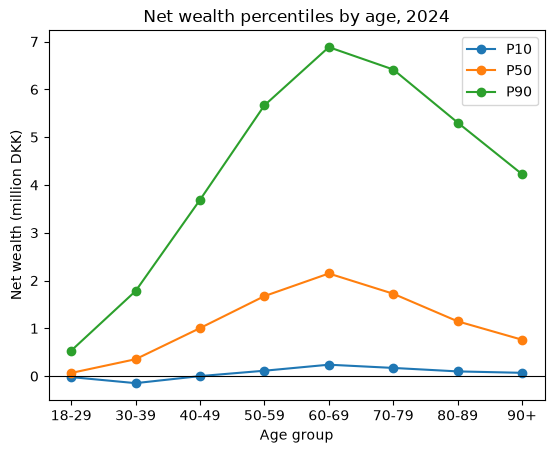

In [ ]:
fig, ax = plt.subplots()

# One line per percentile; divide by 1e6 to show million DKK
ax.plot(pct_table.index, pct_table[10] / 1e6, marker='o', label='P10')
ax.plot(pct_table.index, pct_table[50] / 1e6, marker='o', label='P50')
ax.plot(pct_table.index, pct_table[90] / 1e6, marker='o', label='P90')

ax.axhline(0, color='black', linewidth=0.8)              # horizontal line at zero
ax.set_xlabel('Age group')                               # x-axis
ax.set_ylabel('Net wealth (million DKK)')                # y-axis
ax.set_title('Net wealth percentiles by age, 2024')      # title
ax.legend()

plt.show()

### Question 2

Within each age group we calculate the upper gap (P90 − P50) and the lower gap (P50 − P10) and find the age group with widest upper gap.

In [ ]:
# Upper gap: distance from the median up to the top 10%
pct_table['upper_gap'] = pct_table[90] - pct_table[50]
# Lower gap: distance from the bottom 10% up to the median
pct_table['lower_gap'] = pct_table[50] - pct_table[10]

# Show the relevant columns
pct_table[[10, 50, 90, 'upper_gap', 'lower_gap']]

pct,10,50,90,upper_gap,lower_gap
ALDER,,,,,
18-29,-19750.0,66507.0,532429.0,465922.0,86257.0
30-39,-146586.0,353896.0,1780078.0,1426182.0,500482.0
40-49,912.0,1004750.0,3688269.0,2683519.0,1003838.0
50-59,113324.0,1674287.0,5665305.0,3991018.0,1560963.0
60-69,239280.0,2147564.0,6883537.0,4735973.0,1908284.0
70-79,171695.0,1724056.0,6415595.0,4691539.0,1552361.0
80-89,99096.0,1146853.0,5305568.0,4158715.0,1047757.0
90+,69252.0,761637.0,4225415.0,3463778.0,692385.0


In [ ]:
# Age group with the widest upper gap, and the amount in DKK
print(pct_table['upper_gap'].idxmax())          # show age group
print(pct_table['upper_gap'].max())             # show amount in DKK

60-69
4735973.0


### Question 3

We find for which age group P10 is negative

In [ ]:
# Age groups where P10 is negative
pct_table.loc[pct_table[10] < 0, [10]]

pct,10
ALDER,
18-29,-19750.0
30-39,-146586.0


From the figure in question 1 we see that net wealth follows a similiar path over age, where all three percentiles rise until the 60–69 group and fall afterward. The upper gap (P90 − P50) is widest for the 60–69 group at 4,735,973 DKK
and in every age group it is larger than the lower gap, so the distribution is skewed to the right.

P10 is negative for the 18–29 group (DKK −19,750) and the 30–39 group (DKK −146,586).
One economic reason is that young adults expect higher future income, so they borrow, for example through student loans or mortgages, and build up wealth later in their working life.

Note that the data are one cross-section from 2024, so we compare different people
of different ages, not the same people over time.

## 1.3   Who Has Negative Net Wealth?

### Question 1

Within each age group we divide the number of people in the three brackets below zero by the total number of people, and express it as a percentage.

In [ ]:
# The three wealth brackets below zero (from the FORMUE15 table information)
negative_brackets = ['0000M10', 'M100M05', 'M050000']

# True if the row belongs to a negative bracket
counts_age['negative'] = counts_age['FORMUE'].isin(negative_brackets)

# Number of people per age group: in total and with negative net wealth
total = counts_age.groupby('ALDER')['value'].sum()
negative = counts_age[counts_age['negative']].groupby('ALDER')['value'].sum()

# Share with negative net wealth in percent
share_negative = 100 * negative / total
share_negative

ALDER
1829    12.708092
3039    16.327317
4049     9.345130
5059     5.331294
6069     3.164025
7079     3.040234
8089     2.977995
9099     1.870698
Name: value, dtype: float64

We merge the counts and percentages with the percentile table from 1.2 by age group. 
`validate='1:1'` checks that each age group appears exactly once in both tables.

In [ ]:
# Collect counts and percentages in one DataFrame 
negative_table = pd.DataFrame({'total': total,
                               'negative': negative,
                               'share_negative': share_negative})

# Use the same age labels as pct_table, so the indexes match
negative_table = negative_table.rename(index=age_labels)

# Merge with P10, P50 and P90 from 1.2
age_profile = pd.merge(pct_table[[10, 50, 90]], negative_table,
                       left_index=True, right_index=True, validate='1:1')
age_profile

,10,50,90,total,negative,share_negative
ALDER,,,,,,
18-29,-19750.0,66507.0,532429.0,927354,117849,12.708092
30-39,-146586.0,353896.0,1780078.0,783901,127990,16.327317
40-49,912.0,1004750.0,3688269.0,708080,66171,9.345130
50-59,113324.0,1674287.0,5665305.0,802113,42763,5.331294
60-69,239280.0,2147564.0,6883537.0,709729,22456,3.164025
70-79,171695.0,1724056.0,6415595.0,581304,17673,3.040234
80-89,99096.0,1146853.0,5305568.0,291975,8695,2.977995
90+,69252.0,761637.0,4225415.0,47362,886,1.870698


We plot the percentage by age in a figure.

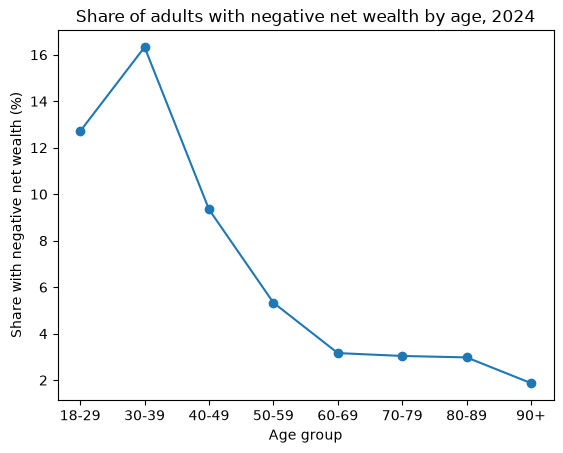

In [ ]:
# Share with negative net wealth by age group
fig, ax = plt.subplots()
ax.plot(age_profile.index, age_profile['share_negative'], marker='o')
ax.set_xlabel('Age group')
ax.set_ylabel('Share with negative net wealth (%)')
ax.set_title('Share of adults with negative net wealth by age, 2024')
plt.show()

We check that the eight age groups sum to the published count for all adults, denoted earlier by `1802`

In [ ]:
# Sum of the eight age groups vs. the published all-adult count
print(age_profile['total'].sum())
print(counts_all['value'].sum())
print(age_profile['total'].sum() == counts_all['value'].sum())   # should be True

4851818
4851818
True


The share with negative net wealth peaks at 16.3% for the 30–39 group and then falls steadily with age, and reaches its lowest at 1.9% for those aged 90+. The eight age counts sum to 4,851,818, the same as the total from the `1802`group.

The median shows a different pattern. It rises until age 60–69 and then falls.
But the share with negative wealth does not rise again when the median falls.
For example, people aged 90+ have a lower median than people aged 50–59,
but fewer of them have negative wealth (1.9% vs. 5.3%).

One reason is that older people have usually paid back most of their loans,
for example their mortgage. So their wealth can be low, but it is rarely below zero.

## 2.1   Give Everybody Their Age-Group Median
Tasks and hints: PDF Section 2.1.

In [ ]:
# Write your simulation function in a .py file next to this notebook and import it here.

**Interpretation.** Write your answer here.

## 2.2   Allow Wealth to Vary Within Each Age Group
Tasks and hints: PDF Section 2.2.

## 2.3   Compare Both Economies with Denmark
Tasks and hints: PDF Section 2.3.

**Interpretation.** Write your answer here.

## 2.4   An Older Denmark
Tasks and hints: PDF Section 2.4.

**Interpretation.** Write your answer here.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).